In [1]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, Input, mixed_precision
from sklearn.model_selection import train_test_split
import cv2
import keras
print("library loaded successfully")
print("*"*100)

I0000 00:00:1788530090.757328    7941 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


library loaded successfully
****************************************************************************************************


In [26]:
IMG_SIZE = 256  # Standardized input resolution for both phases
BATCH_SIZE = 4 # Batch size
EPOCHS_PHASE1 = 150  # Semantic Segmentation Focus, for Segmentation 

In [2]:
# Directory and Artifact Paths
DATA_PATH = '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2'
POSITIVE_DIR = os.path.join(DATA_PATH, 'imagesAll_positive') # For Polyp classification
NEGATIVE_DIR = os.path.join(DATA_PATH, 'sequenceData/negativeOnly')  # For non polyp classification
MODEL_SAVE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/tr-net-rnd.keras"

In [3]:
def augment(img, mask):
    """Applies shape-preserving geometric and radiometric transformations."""
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_left_right(img)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_up_down(img)
        mask = tf.image.flip_up_down(mask)
    
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    img = tf.clip_by_value(img, 0.0, 1.0)
    
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return img, mask

In [4]:
import os
import glob
import random
import numpy as np

def load_balanced_segmentation_paths(base_path):
    """
    Compiles a highly organized dataset from Multi-Center (C1-C6) and Video Sequences
    enforcing a strict 75% Positive and 25% Negative ratio.
    """
    valid_exts = ('*.jpg', '*.JPG', '*.jpeg', '*.JPEG', '*.png', '*.PNG')
    
    pos_images = []
    pos_masks = []
    neg_images = []
    neg_masks = []
    
    print("⏳ Stage 1: Extracting Multi-Center (C1-C6) Positive Static Data...")
    for i in range(1, 7):
        center_id = f"C{i}"
        img_dir = os.path.join(base_path, f"data_{center_id}", f"images_{center_id}")
        mask_dir = os.path.join(base_path, f"data_{center_id}", f"masks_{center_id}")
        
        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            center_img_paths = []
            for ext in valid_exts:
                center_img_paths.extend(glob.glob(os.path.join(img_dir, ext)))
                
            for img_p in center_img_paths:
                filename = os.path.basename(img_p)
                name_without_ext, ext = os.path.splitext(filename)
            
                expected_mask_name = f"{name_without_ext}_mask{ext}"
                mask_p = os.path.join(mask_dir, expected_mask_name)
                
                if os.path.exists(mask_p):
                    pos_images.append(img_p)
                    pos_masks.append(mask_p)

    print(f"✓ Static Core Loaded. Total C1-C6 Pairs: {len(pos_images)}")
    
    print("\n⏳ Stage 2: Extracting Positive Sequence Data (seq1 - seq23)...")

    for i in range(1, 24):
        seq_dir = os.path.join(base_path, "sequenceData", "positive", f"seq{i}")
        img_dir = os.path.join(seq_dir, f"images_seq{i}")
        mask_dir = os.path.join(seq_dir, f"masks_seq{i}")
        
        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            seq_img_paths = []
            for ext in valid_exts:
                seq_img_paths.extend(glob.glob(os.path.join(img_dir, ext)))
                
            for img_p in seq_img_paths:
                filename = os.path.basename(img_p)
                name_without_ext, ext = os.path.splitext(filename)
        
                expected_mask_name = f"{name_without_ext}_mask{ext}"
                mask_p = os.path.join(mask_dir, expected_mask_name)
                
                if os.path.exists(mask_p):
                    pos_images.append(img_p)
                    pos_masks.append(mask_p)

    total_positive_available = len(pos_images)
    print(f"✓ Positive Sequences Integrated. Total Global Positive Data: {total_positive_available}")
    
    print("\n⏳ Stage 3: Harvesting All Available Negative Sequence Data (seq1_neg - seq13_neg)...")
    all_raw_neg_images = []
    for i in range(1, 14):
        neg_seq_dir = os.path.join(base_path, "sequenceData", "negativeOnly")
        img_dir = os.path.join(neg_seq_dir, f"seq{i}_neg")
        
        if os.path.exists(img_dir):
            for ext in valid_exts:
                all_raw_neg_images.extend(glob.glob(os.path.join(img_dir, ext)))
                
    print(f"✓ Raw Negative Frames Discovered: {len(all_raw_neg_images)}")


    target_negative_count = int(total_positive_available / 3)
    
    if len(all_raw_neg_images) >= target_negative_count:
        random.seed(42) 
        selected_neg_images = random.sample(all_raw_neg_images, target_negative_count)
    else:
        print(f"⚠️ Warning: Not enough negative images to fulfill 25% ratio perfectly. Using all available.")
        selected_neg_images = all_raw_neg_images

    for neg_img in selected_neg_images:
        neg_images.append(neg_img)
        neg_masks.append("VIRTUAL_BLACK_MASK")


    final_images = pos_images + neg_images
    final_masks = pos_masks + neg_masks
    
    combined = list(zip(final_images, final_masks))
    random.seed(42)
    random.shuffle(combined)
    final_images, final_masks = zip(*combined)
    
    actual_pos_pct = (len(pos_images) / len(final_images)) * 100
    actual_neg_pct = (len(neg_images) / len(final_images)) * 100
    
    print("\n=======================================================")
    print("🏆 PIPELINE DATASET COMPILED SUCCESSFULLY")
    print("=======================================================")
    print(f"➔ Total Dataset Size   : {len(final_images)} Frames")
    print(f"➔ Total Positive Pool  : {len(pos_images)} ({actual_pos_pct:.2f}%)")
    print(f"➔ Total Negative Pool  : {len(neg_images)} ({actual_neg_pct:.2f}%)")
    print("=======================================================")
    
    return list(final_images), list(final_masks)

In [5]:
import cv2
import numpy as np
import tensorflow as tf
import random

def process_path_segmentation(img_path, mask_path):
    """
    Advanced Preprocessing Wrapper for Dataset B.
    Applies CLAHE, Median Blur, Mild Sharpening, and dynamic black mask generation.
    """
    def _read_and_process(img_p, mask_p):
        # Decode tensor bytes to native python strings safely
        img_p_str = img_p.numpy().decode('utf-8') if hasattr(img_p, 'numpy') else img_p.decode('utf-8')
        mask_p_str = mask_p.numpy().decode('utf-8') if hasattr(mask_p, 'numpy') else mask_p.decode('utf-8')
        
        # ─── STEP 1: IMAGE LOADING & INITIAL RESIZING ───
        img = cv2.imread(img_p_str)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        
        # ─── STEP 2: DYNAMIC MASK HANDLING ───
        # Check if the mask path is the designated virtual tag for negative samples
        if mask_p_str == "VIRTUAL_BLACK_MASK":
            # Generate a clean, all-black matrix dynamically in-memory
            mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
        else:
            # Load the regular ground-truth mask from disk for positive samples
            mask = cv2.imread(mask_p_str, cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        
        # ─── STEP 3: CONTRAST ENHANCEMENT (CLAHE) ───
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)
        
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l_channel)
        
        limg = cv2.merge((cl, a_channel, b_channel))
        enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
        median_blur = cv2.medianBlur(enhanced_img, 3) 
        
        # ─── STEP 4: MILD SHARPENING ───
        sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
        
        # ─── STEP 5: NORMALIZATION & THRESHOLDING ───
        normalized_img = sharpened / 255.0
        normalized_mask = mask / 255.0
        normalized_mask = np.where(normalized_mask > 0.5, 1.0, 0.0)
        
        # Expand dimensions to ensure channel axis exists (IMG_SIZE, IMG_SIZE, 1)
        normalized_mask = np.expand_dims(normalized_mask, axis=-1)
        
        return normalized_img.astype(np.float32), normalized_mask.astype(np.float32)

    # Execute the python logic inside TensorFlow data pipeline graph
    [img_tensor, mask_tensor] = tf.py_function(
        _read_and_process, 
        [img_path, mask_path], 
        [tf.float32, tf.float32]
    )
    
    # Enforce strict static shapes for TensorFlow graph stability
    img_tensor.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask_tensor.set_shape([IMG_SIZE, IMG_SIZE, 1])
    
    return img_tensor, mask_tensor

In [6]:
def load_segmentation_paths(base_path):
    """Extracts paired image and mask absolute paths from multi-center repositories."""
    all_images, all_masks = [], []
    for i in range(1, 7):
        center_id = f"C{i}"
        img_dir = os.path.join(base_path, f"data_{center_id}", f"images_{center_id}")
        mask_dir = os.path.join(base_path, f"data_{center_id}", f"masks_{center_id}")
        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            img_paths = (glob.glob(os.path.join(img_dir, "*.jpg")) + glob.glob(os.path.join(img_dir, "*.JPG")) +
                         glob.glob(os.path.join(img_dir, "*.png")) + glob.glob(os.path.join(img_dir, "*.jpeg")))
            for img_p in img_paths:
                filename = os.path.basename(img_p)
                name_without_ext, ext = os.path.splitext(filename)
                expected_mask_name = f"{name_without_ext}_mask{ext}"
                mask_p = os.path.join(mask_dir, expected_mask_name)
                if os.path.exists(mask_p):
                    all_images.append(img_p)
                    all_masks.append(mask_p)
    return all_images, all_masks

In [7]:
def se_block(input_tensor, ratio=16):
    """Channel-wise Squeeze-and-Excitation Attention Layer."""
    channels = input_tensor.shape[-1]
    squeeze = layers.GlobalAveragePooling2D()(input_tensor)
    excitation = layers.Dense(channels // ratio, activation='relu', use_bias=False)(squeeze)
    excitation = layers.Dense(channels, activation='sigmoid', use_bias=False)(excitation)
    excitation = layers.Reshape((1, 1, channels))(excitation)
    return layers.multiply([input_tensor, excitation])


In [20]:
def depthwise_seperable_conv_block(x, filters, dropout_rate=0.0, name_prefix=""):
    """Multi-Scale Parallel Kernels (3x3, 5x5, 7x7, 1x1) with Depthwise Separable Convolutions."""
    f4 = filters // 4
    b3 = layers.SeparableConv2D(f4, 3, padding='same', use_bias=False, name=f"{name_prefix}_3x3")(x)
    b3 = layers.BatchNormalization()(b3); b3 = layers.Activation('relu')(b3)
    
    b5 = layers.SeparableConv2D(f4, 5, padding='same', use_bias=False, name=f"{name_prefix}_5x5")(x)
    b5 = layers.BatchNormalization()(b5); b5 = layers.Activation('relu')(b5)
    
    b7 = layers.SeparableConv2D(f4, 7, padding='same', use_bias=False, name=f"{name_prefix}_7x7")(x)
    b7 = layers.BatchNormalization()(b7); b7 = layers.Activation('relu')(b7)
    
    b1 = layers.SeparableConv2D(f4, 1, padding='same', use_bias=False, name=f"{name_prefix}_1x1")(x)
    b1 = layers.BatchNormalization()(b1); b1 = layers.Activation('relu')(b1)
    
    merged = layers.Concatenate(name=f"{name_prefix}_concat")([b3, b5, b7, b1])
    x_se = merged #se_block(merged, ratio=16) 
    # Feed-forward Network Integration
    if x.shape[-1] == filters:
        x_se = layers.add([x, x_se], name=f"{name_prefix}_residual")
    if dropout_rate > 0:
        x_se = layers.SpatialDropout2D(dropout_rate, name=f"{name_prefix}_dropout")(x_se)
    return x_se

In [9]:
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    """Natively computes spatial Pearson Correlation Coefficients within the network graph."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        # We used epsilon sothat standard deviation value cannot be zero, otherwise code will crash
        epsilon = 1e-8
        # finds the average standard deviaiton
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        # data normalization or (Z-Score)
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)

In [10]:
def build_unified_segmentation_based_model(input_shape=(256, 256, 3)):
    """
    Constructs a dual-headed multi-task Y-Net architecture.
    Shares a deeply regularized, multi-scale latent space to simultaneously
    perform semantic image segmentation and unified scene classification.
    Integrated with Deep Supervision along the decoder pathway for SOTA convergence.
    """
    # [Input Layer]: Defines the input tensor shape holding the raw 3-channel RGB medical images.
    inputs = Input(shape=input_shape, name="shared_input_image")

    # ── Shared Custom Multi-Scale Encoder ─────────────────────────────────────
    # [Enc Block 1]: Processes raw input into 32 multi-scale feature channels. Output dim: (256, 256, 32)
    c1 = depthwise_seperable_conv_block(inputs, 32, name_prefix="enc_c1")
    # [Max Pooling 1]: Downsamples spatial dimensions by a factor of 2. Dim: (128, 128, 32)
    p1 = layers.MaxPooling2D(2, name="enc_p1")(c1)

    # [Enc Block 2]: Extracts deeper geometric abstractions into 64 semantic channels. Output dim: (128, 128, 64)
    c2 = depthwise_seperable_conv_block(p1, 64, name_prefix="enc_c2")
    # [Max Pooling 2]: Downsamples spatial dimensions further. Dim: (64, 64, 64)
    p2 = layers.MaxPooling2D(2, name="enc_p2")(c2)

    # [Enc Block 3]: Scales representation to 128 channels. Dim: (64, 64, 128)
    c3 = depthwise_seperable_conv_block(p2, 128, dropout_rate=0.1, name_prefix="enc_c3")
    # [Max Pooling 3]: Reduces resolution further. Dim: (32, 32, 128)
    p3 = layers.MaxPooling2D(2, name="enc_p3")(c3)

    # [Enc Block 4]: Captures high-level contextual abstracts across 256 channels. Dim: (32, 32, 256)
    c4 = depthwise_seperable_conv_block(p3, 256, dropout_rate=0.2, name_prefix="enc_c4")
    # [Max Pooling 4]: Compresses spatial grid to its lowest native encoder resolution. Dim: (16, 16, 256)
    p4 = layers.MaxPooling2D(2, name="enc_p4")(c4)
    
    # ── Shared Representation Latent Bottleneck ───────────────────────────────
    # [Shared Bottleneck]: Maps the compressed grid into a highly dense 512-channel latent feature space. Dim: (16, 16, 512)
    b = depthwise_seperable_conv_block(p4, 512, dropout_rate=0.3, name_prefix="shared_bottleneck")

    # ── Output Branch A: Semantic Segmentation Decoder with Deep Supervision ──
    # [Upsampling 4]: Uses learned transpose convolution filters to upscale the latent grid. Dim: (32, 32, 256)
    u4 = layers.Conv2DTranspose(256, 2, strides=2, padding='same', name="dec_u4")(b)
    # [Skip Connection 4]: Concatenates low-level encoder features (c4). Total channels: 256 + 256 = 512
    u4 = layers.concatenate([u4, c4], name="dec_concat_4")
    # [Dec Block 5]: Regularizes concatenated representation back to 256 optimized features. Dim: (32, 32, 256)
    c5 = depthwise_seperable_conv_block(u4, 256, dropout_rate=0.2, name_prefix="dec_c5")

    # Deep Supervision process integration
    ds1 = layers.Conv2D(1, 1, padding='same', name='ds1_conv')(c5)
    ds1 = layers.UpSampling2D(size=(8, 8), interpolation='bilinear', dtype='float32', name='ds1_output')(ds1)

    # [Upsampling 3]: Expands spatial dimensions. Dim: (64, 64, 128)
    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding='same', name="dec_u3")(c5)
    # [Skip Connection 3]: Merges encoder's mid-level details (c3). Total channels: 128 + 128 = 256
    u3 = layers.concatenate([u3, c3], name="dec_concat_3")
    # [Dec Block 6]: Consolidates features. Dim: (64, 64, 128)
    c6 = depthwise_seperable_conv_block(u3, 128, dropout_rate=0.1, name_prefix="dec_c6")

    ds2 = layers.Conv2D(1, 1, padding='same', name='ds2_conv')(c6)
    ds2 = layers.UpSampling2D(size=(4, 4), interpolation='bilinear', dtype='float32', name='ds2_output')(ds2)

    # [Upsampling 2]: Output dim: (128, 128, 64)
    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding='same', name="dec_u2")(c6)
    # [Skip Connection 2]: Re-introduces high-resolution textures from c2. Total channels: 64 + 64 = 128
    u2 = layers.concatenate([u2, c2], name="dec_concat_2")
    # [Dec Block 7]: Harmonizes maps into 64 channels. Dim: (128, 128, 64)
    c7 = depthwise_seperable_conv_block(u2, 64, name_prefix="dec_c7")


    ds3 = layers.Conv2D(1, 1, padding='same', name='ds3_conv')(c7)
    ds3 = layers.UpSampling2D(size=(2, 2), interpolation='bilinear', dtype='float32', name='ds3_output')(ds3)

    # [Upsampling 1]: Restores feature maps back to the original input spatial size. Output dim: (256, 256, 32)
    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding='same', name="dec_u1")(c7)
    # [Skip Connection 1]: Concat-links raw spatial coordinates directly from c1. Total channels: 32 + 32 = 64
    u1 = layers.concatenate([u1, c1], name="dec_concat_1")
    # [Dec Block 8]: Refines final decoded features. Dim: (256, 256, 32)
    c8 = depthwise_seperable_conv_block(u1, 32, name_prefix="dec_c8")

    # [Main Segmentation Mask Output]: ওরিজিনাল ফাইনাল আউটপুট
    segmentation_output = layers.Conv2D(1, 1, activation='sigmoid', dtype='float32', name='seg_output')(c8)

    # ── Output Branch B: Segmentation-Guided Classification Head ──────────────
    # [Classification CNN]: Performs light 3x3 depthwise separable convolution. Dim: (16, 16, 32)
    pd_cnn = layers.SeparableConv2D(32, (3, 3), padding='same', activation='relu', name="clf_pd_cnn")(b)
    # [Max Pooling]: Downsamples classification maps spatially. Output dim: (8, 8, 32)
    p_pool = layers.MaxPooling2D((2, 2), name="clf_maxpool")(pd_cnn)
    
    # [Global Average Pooling (GAP)]: Collapses spatial dimensions into a single vector.
    flat_features = layers.GlobalAveragePooling2D(name="clf_gap")(p_pool)
    # [Keras PCC Layer]: Computes Linear statistical dependency.
    pcc_features = KerasPCCLayer(name="clf_pcc_layer")(flat_features)
    # [Z-Score Normalization]: Stabilizes dense convergence.
    standardized = layers.BatchNormalization(name="clf_zscore_bn")(pcc_features)
    
    # [Fully Connected Dense]: Learns non-linear correlation.
    d1 = layers.Dense(64, activation='relu', name="clf_dense1")(standardized)
    # [Dropout]: Prevent Overfitting
    d1 = layers.Dropout(0.3, name="clf_dropout")(d1)
    # [Classification Score Output]: Yields global disease probability.
    classification_output = layers.Dense(1, activation='sigmoid', dtype='float32', name='clf_output')(d1)

    # ── [Model Compilation Graph Finalization] ────────────────────────────────
    return models.Model(
        inputs=inputs, 
        outputs=[segmentation_output, ds1, ds2, ds3, classification_output], 
        name="Thesis_DeepSupervised_YNet"
    )

In [11]:
@keras.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)


In [12]:
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

In [13]:
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)

In [14]:
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=0.75):
    """
    Focal Tversky Loss for imbalanced medical image segmentation.
    alpha: controls penalty for False Negatives (FN) -> keeping it higher (0.7) focuses on small polyps.
    beta: controls penalty for False Positives (FP).
    """
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Calculate True Positives, False Negatives, and False Positives
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Tversky Index
    smooth = 1e-6
    tversky_index = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    
    # Focal Tversky Loss
    return tf.math.pow((1.0 - tversky_index), gamma)

In [15]:
@keras.saving.register_keras_serializable()
def iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)

In [16]:
@keras.saving.register_keras_serializable()
def tnr_metric(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)

    true_negatives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * (1.0 - y_pred_f), tf.float32))
    false_positives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * y_pred_f, tf.float32))
    
    # TNR = TN / (TN + FP)
    return (true_negatives + 1e-7) / (true_negatives + false_positives + 1e-7)

In [17]:
@keras.saving.register_keras_serializable()
def mean_iou_metric(y_true, y_pred):
    # Flatten the matrices to 1D tensors to calculate pixel-level metrics
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Apply hard thresholding (Same as your F2 and Dice implementation)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    # Calculate basic confusion matrix components for the positive class (Polyp)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    
    # Calculate True Negatives (TN) which represents correctly classified background pixels
    tn = tf.reduce_sum((1.0 - y_true_f) * (1.0 - y_pred_f))

    # ─── 🎯 STEP 1: CALCULATE IoU FOR POLYP CLASS (Positive Class) ───
    polyp_iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
    
    # ─── 🌍 STEP 2: CALCULATE IoU FOR BACKGROUND CLASS (Negative Class) ───
    # For background: TN is True Positive, FN becomes False Positive, and FP becomes False Negative
    bg_iou = (tn + 1e-7) / (tn + fn + fp + 1e-7)
    
    # ─── 📊 STEP 3: COMPUTE THE MEAN (AVERAGE) IoU OF BOTH CLASSES ───
    mIoU = (polyp_iou + bg_iou) / 2.0
    
    return mIoU

In [18]:
@keras.saving.register_keras_serializable()
def f2_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))

    numerator = 5.0 * tp + 1e-7
    denominator = 5.0 * tp + 4.0 * fn + fp + 1e-7
    
    return numerator / denominator

In [19]:
@keras.saving.register_keras_serializable()
def precision_segmentation(y_true, y_pred):
    # Flatten the matrices to 1D tensors to calculate pixel-level metrics
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Apply hard thresholding (Same as your F2 and mIoU implementation)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    # Calculate True Positives (TP) and False Positives (FP)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Precision Formula: TP / (TP + FP)
    # Adding a tiny epsilon (1e-7) to completely avoid zero division errors
    numerator = tp + 1e-7
    denominator = tp + fp + 1e-7
    
    return numerator / denominator

In [24]:

def load_classification_paths():
    """Compiles absolute paths for global positive and artifact-heavy negative sequences."""
    valid_exts = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.tif', '*.PNG', '*.JPG', '*.JPEG')
    pos_files, neg_files = [], []
    
    # 1. Gather all positive paths
    for ext in valid_exts:
        pos_files.extend(glob.glob(os.path.join(POSITIVE_DIR, "**", ext), recursive=True))
        
    # 2. Gather all negative paths from seq1 to seq13
    for i in range(1, 14):
        target_folder = os.path.join(NEGATIVE_DIR, f"seq{i}_neg")
        if os.path.exists(target_folder):
            for ext in valid_exts:
                neg_files.extend(glob.glob(os.path.join(target_folder, "**", ext), recursive=True))
                
    # Filter to ensure only valid files are kept
    pos_files = [f for f in pos_files if os.path.isfile(f)]
    neg_files = [f for f in neg_files if os.path.isfile(f)]
    
    # ─── 🚀 🆕 STEP 3: STRICT 50% - 50% BALANCING LOGIC ───
    min_samples = min(len(pos_files), len(neg_files))
    print(f"\n📊 Raw Counts -> Polyp: {len(pos_files)} | Non-Polyp: {len(neg_files)}")
    print(f"⚖️ Balancing Dataset at Sweet Spot: {min_samples} samples each (Total: {min_samples * 2})")
    
    # Randomly shuffle before trimming to ensure diversity
    np.random.seed(42)
    np.random.shuffle(pos_files)
    np.random.shuffle(neg_files)
    
    # Slice both lists to have the exact same size
    pos_files = pos_files[:min_samples]
    neg_files = neg_files[:min_samples]
    print("positive files", len(pos_files), "neg files", len(neg_files))
    # ──────────────────────────────────────────────────────
    
    file_paths = pos_files + neg_files
    labels = [1.0] * len(pos_files) + [0.0] * len(neg_files)
    
    return np.array(file_paths), np.array(labels, dtype=np.float32)

In [27]:
# # Initialize allocation strategy for physical compute hardware by scanning for available GPU units.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus: tf.config.experimental.set_memory_growth(gpu, True)
        print("✓ Tensor Graph Allocation Locked over available GPU nodes.")
    except RuntimeError as e: print(e)

# 1. PARSE PIPELINE DIRECTORIES
print("\n[Data Ingestion] Parsing Multi-Center Localization Data (Dataset B)...")
seg_imgs, seg_masks = load_segmentation_paths(DATA_PATH)
s_train_x, s_val_x, s_train_y, s_val_y = train_test_split(seg_imgs, seg_masks, test_size=0.2, random_state=42)

print("[Data Ingestion] Parsing Balanced Sequence Arrays (Dataset A)...")
clf_imgs, clf_labels = load_classification_paths()
indices = np.arange(len(clf_imgs))
np.random.seed(42); np.random.shuffle(indices)
clf_imgs, clf_labels = clf_imgs[indices], clf_labels[indices]
c_split = int(0.8 * len(clf_imgs))

# 2. GENERATE HIGH-THROUGHPUT ITERATORS
print("\n⚡ Initializing Multi-Threaded High-Throughput Iterators via AUTOTUNE...")

# --- Segmentation Datasets ---
train_seg_ds = tf.data.Dataset.from_tensor_slices((s_train_x, s_train_y)) \
    .shuffle(len(s_train_x)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

val_seg_ds = tf.data.Dataset.from_tensor_slices((s_val_x, s_val_y)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)


train_clf_ds = tf.data.Dataset.from_tensor_slices((clf_imgs[:c_split], clf_labels[:c_split])) \
    .shuffle(1024) \
    .map(process_path_classification, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

val_clf_ds = tf.data.Dataset.from_tensor_slices((clf_imgs[c_split:], clf_labels[c_split:])) \
    .map(process_path_classification, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

# 3. GRAPH INSTANTIATION
print("\n🏗️ Compiling Dual-Head Computation Topology...")
model = build_unified_segmentation_based_model()

# 🌟 STAGE 1: SEMANTIC SEGMENTATION MAXIMIZATION (Dataset B Only)
print("\n=======================================================")
print("[PHASE 1] Optimizing Localization Ensembles & Structural Layers")
print("=======================================================")

# Freeze classification branch entirely to avoid uninitialized variable gradients
for layer in model.layers:
    if "clf_" in layer.name:
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=mixed_precision.LossScaleOptimizer(tf.keras.optimizers.Adam(learning_rate=1e-3)),
    loss=[focal_tversky_loss, None],
    #metrics=[[dice_coef, iou_metric, 'accuracy'], []]
    metrics = {
        'seg_output': [
            'accuracy',                                      
            tf.keras.metrics.Recall(name='recall'),          
            tnr_metric,
            dice_coef,
            iou_metric,
            f2_segmentation,
            mean_iou_metric,
            precision_segmentation
        ]
    }
)




# ── FIXED CALLBACKS FOR PHASE 1 ──────────────────────────────────────────
phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_seg_output_dice_coef', save_best_only=True, mode='max', verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-4, verbose=1)
]

# PHASE 1 Training started ...
history_p1 = model.fit(train_seg_ds, validation_data=val_seg_ds, epochs=EPOCHS_PHASE1, callbacks=phase1_callbacks, verbose=1)
print("[PHASE 1 COMPLETE] Spatial boundaries locked successfully.")




✓ Tensor Graph Allocation Locked over available GPU nodes.

[Data Ingestion] Parsing Multi-Center Localization Data (Dataset B)...
[Data Ingestion] Parsing Balanced Sequence Arrays (Dataset A)...

📊 Raw Counts -> Polyp: 3762 | Non-Polyp: 2520
⚖️ Balancing Dataset at Sweet Spot: 2520 samples each (Total: 5040)
positive files 2520 neg files 2520

⚡ Initializing Multi-Threaded High-Throughput Iterators via AUTOTUNE...

🏗️ Compiling Dual-Head Computation Topology...

[PHASE 1] Optimizing Localization Ensembles & Structural Layers
Epoch 1/150


/mnt/c/development/Thesis/PotatoDiseaseClassification-CNN/linux-venv/lib/python3.12/site-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['ds1_conv/kernel', 'ds1_conv/bias', 'ds2_conv/kernel', 'ds2_conv/bias', 'ds3_conv/kernel', 'ds3_conv/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(
I0000 00:00:1788530824.085573   14662 service.cc:153] XLA service 0x714b0c125d40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1788530824.085652   14662 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1788530824.809405   14662 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1788530830.399176   14662 cuda_dnn.cc:461] Loaded cu

307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - loss: 0.7285 - seg_output_accuracy: 0.6840 - seg_output_dice_coef: 0.2586 - seg_output_f2_segmentation: 0.4320 - seg_output_iou_metric: 0.1699 - seg_output_mean_iou_metric: 0.4163 - seg_output_precision_segmentation: 0.1814 - seg_output_recall: 0.7797 - seg_output_tnr_metric: 0.6412
Epoch 1: val_seg_output_dice_coef improved from None to 0.31436, saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/tr-net-rnd.keras

Epoch 1: finished saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/tr-net-rnd.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 134s 134ms/step - loss: 0.7043 - seg_output_accuracy: 0.7341 - seg_output_dice_coef: 0.2881 - seg_output_f2_segmentation: 0.4483 - seg_output_iou_metric: 0.1864 - seg_output_mean_iou_metric: 0.4518 - seg_output_precision_segmentation: 0.2036 - seg_output_recall: 0.7402 - seg_output_tnr_metric: 0.7124 - val_loss: 0.6932 - val_seg_ou


📈 [Visuals] Plotting Phase-1 Segmentation History (Train vs Val)...
📊 Mapping Keys Automatically -> Dice: 'seg_output_dice_coef', IoU: 'seg_output_iou_metric', Accuracy: 'seg_output_accuracy'


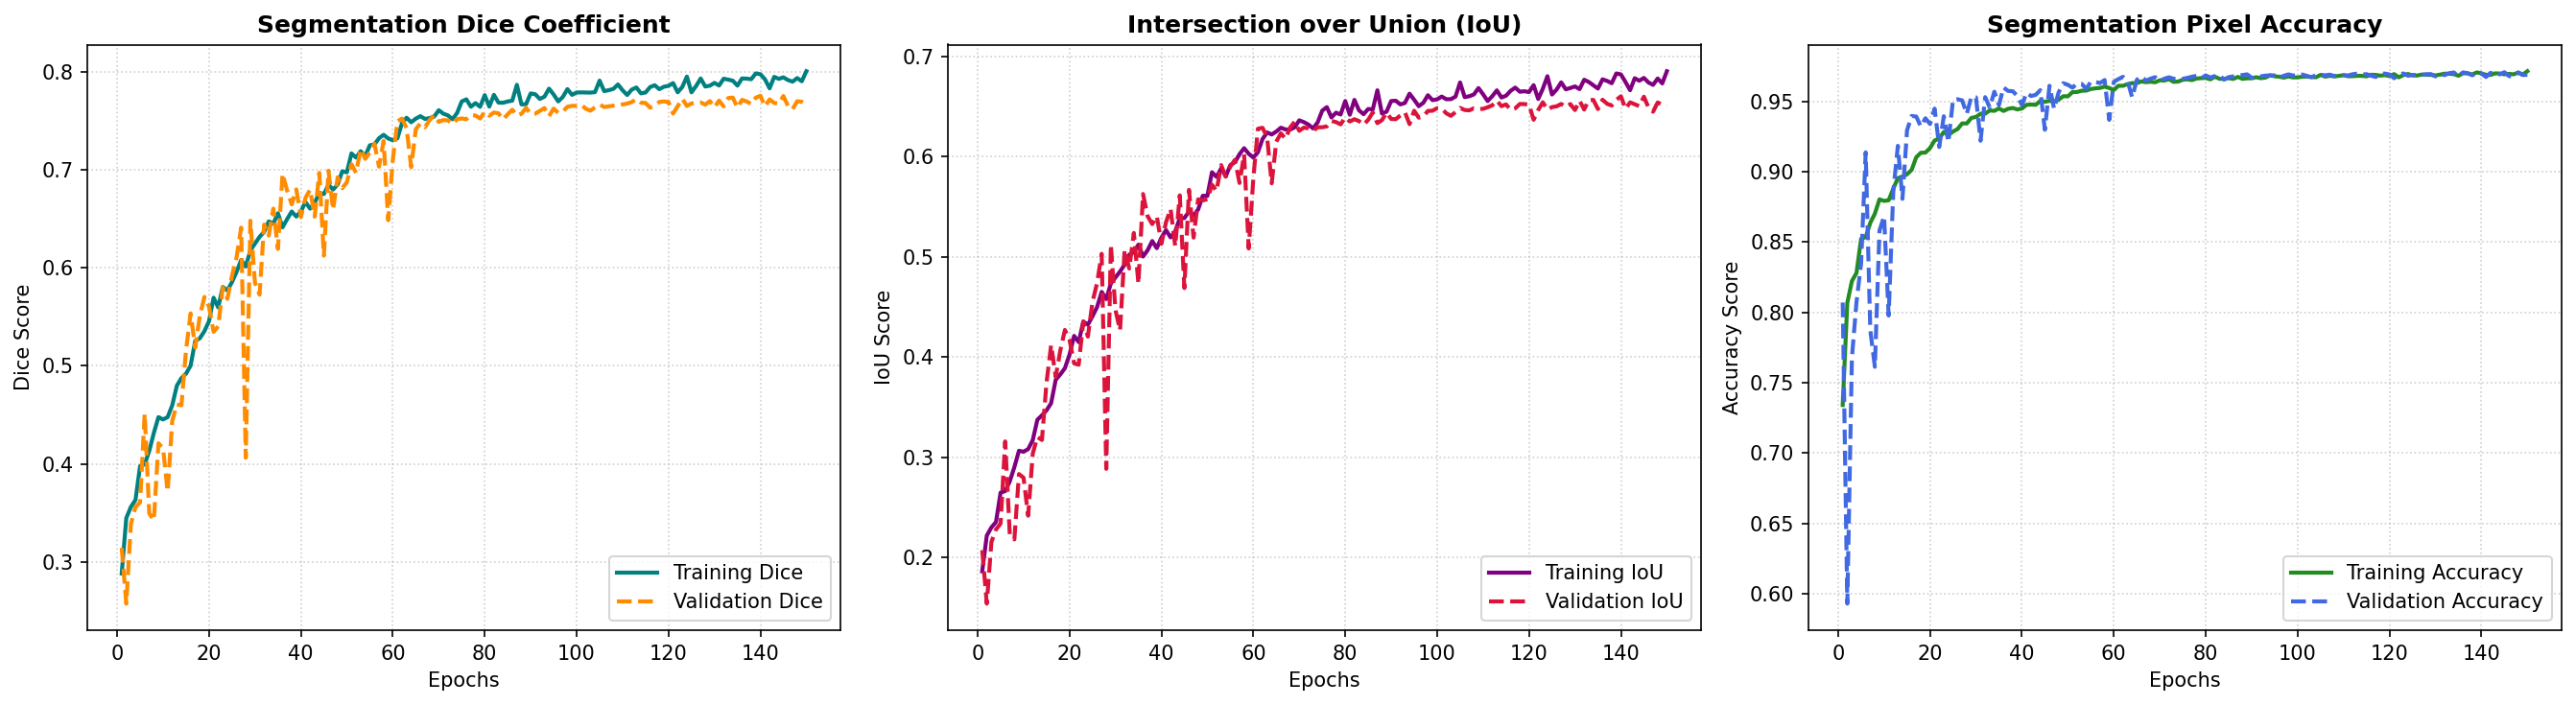

💾 Saved: segmentation_train_val_metrics04.png


In [28]:
# ─────────────────────────────────────────────────────────────────────────────
# 📈 PHASE 1: SEGMENTATION LEARNING CURVES (TRAIN VS VALIDATION) - DYNAMIC FIX
# ─────────────────────────────────────────────────────────────────────────────
print("\n📈 [Visuals] Plotting Phase-1 Segmentation History (Train vs Val)...")
history_dict = history_p1.history 
epochs_range = range(1, len(history_dict['loss']) + 1)

dice_key = [k for k in history_dict.keys() if 'dice' in k and 'val' not in k][0]
val_dice_key = [k for k in history_dict.keys() if 'dice' in k and 'val' in k][0]

iou_key = [k for k in history_dict.keys() if 'iou' in k and 'val' not in k][0]
val_iou_key = [k for k in history_dict.keys() if 'iou' in k and 'val' in k][0]


acc_key = [k for k in history_dict.keys() if ('acc' in k or 'accuracy' in k) and 'val' not in k and 'dice' not in k and 'iou' not in k][0]
val_acc_key = [k for k in history_dict.keys() if ('acc' in k or 'accuracy' in k) and 'val' in k and 'dice' not in k and 'iou' not in k][0]

print(f"📊 Mapping Keys Automatically -> Dice: '{dice_key}', IoU: '{iou_key}', Accuracy: '{acc_key}'")

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), dpi=150)

# 1. Dice Coefficient Curve (Train vs Val)
axes[0].plot(epochs_range, history_dict[dice_key], color='teal', lw=2, label='Training Dice')
axes[0].plot(epochs_range, history_dict[val_dice_key], color='darkorange', lw=2, linestyle='--', label='Validation Dice')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].set_title('Segmentation Dice Coefficient', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs', fontsize=10)
axes[0].set_ylabel('Dice Score', fontsize=10)
axes[0].legend(loc='lower right')

# 2. IoU Metric Curve (Train vs Val)
axes[1].plot(epochs_range, history_dict[iou_key], color='purple', lw=2, label='Training IoU')
axes[1].plot(epochs_range, history_dict[val_iou_key], color='crimson', lw=2, linestyle='--', label='Validation IoU')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].set_title('Intersection over Union (IoU)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epochs', fontsize=10)
axes[1].set_ylabel('IoU Score', fontsize=10)
axes[1].legend(loc='lower right')

# 3. Pixel Accuracy Curve (Train vs Val)
axes[2].plot(epochs_range, history_dict[acc_key], color='forestgreen', lw=2, label='Training Accuracy')
axes[2].plot(epochs_range, history_dict[val_acc_key], color='royalblue', lw=2, linestyle='--', label='Validation Accuracy')
axes[2].grid(True, linestyle=':', alpha=0.6)
axes[2].set_title('Segmentation Pixel Accuracy', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epochs', fontsize=10)
axes[2].set_ylabel('Accuracy Score', fontsize=10)
axes[2].legend(loc='lower right')

plt.tight_layout()
plt.show()
print("💾 Saved: segmentation_train_val_metrics04.png")

In [29]:
# =============================================================================
# 📊 PRINT PEAK PERFORMANCE METRICS FOR THESIS REPORT
# =============================================================================
print("=====================================================================")
print("🏆 Unified Model: Peak Performance Metrics (Phase 1 & Phase 2)")
print("=====================================================================")

# 🧠 1. PHASE 1: SEMANTIC SEGMENTATION PERFORMANCE
h1 = history_p1.history


dice_key = [k for k in h1.keys() if 'dice' in k and 'val' not in k][0]
val_dice_key = [k for k in h1.keys() if 'dice' in k and 'val' in k][0]
iou_key = [k for k in h1.keys() if 'iou' in k and 'val' not in k][0]
val_iou_key = [k for k in h1.keys() if 'iou' in k and 'val' in k][0]
miou_key = [k for k in h1.keys() if 'mean_iou' in k and 'val' not in k][0]
val_miou_key = [k for k in h1.keys() if 'mean_iou' in k and 'val' in k][0]
loss_key = [k for k in h1.keys() if 'loss' in k and 'val' not in k][0]
val_loss_key = [k for k in h1.keys() if 'loss' in k and 'val' in k][0]

acc_key = [k for k in h1.keys() if ('acc' in k or 'accuracy' in k) and 'val' not in k][0]
val_acc_key = [k for k in h1.keys() if ('acc' in k or 'accuracy' in k) and 'val' in k][0]
rec_key = [k for k in h1.keys() if 'recall' in k and 'val' not in k][0]
val_rec_key = [k for k in h1.keys() if 'recall' in k and 'val' in k][0]
tnr_key = [k for k in h1.keys() if 'tnr' in k and 'val' not in k][0]
val_tnr_key = [k for k in h1.keys() if 'tnr' in k and 'val' in k][0]
# ─── 🚀 🆕 DYNAMICALLY EXTRACTING PRECISION KEYS ───
prec_key = [k for k in h1.keys() if 'precision' in k and 'val' not in k][0]
val_prec_key = [k for k in h1.keys() if 'precision' in k and 'val' in k][0]

best_p1_idx = np.argmax(h1[val_dice_key])


def calculate_f2(dice_val, recall_val):
    # To handle zero division edge cases safely
    if (2 * recall_val - dice_val) <= 0 or recall_val == 0:
        return 0.0
    precision_derived = (dice_val * recall_val) / (2 * recall_val - dice_val)
    if (4 * precision_derived + recall_val) == 0:
        return 0.0
    f2_score = (5 * precision_derived * recall_val) / (4 * precision_derived + recall_val)
    return f2_score

train_f2_score = calculate_f2(h1[dice_key][best_p1_idx], h1[rec_key][best_p1_idx])
val_f2_score = calculate_f2(h1[val_dice_key][best_p1_idx], h1[val_rec_key][best_p1_idx])

print(f"\n📍 [PHASE 1: SEGMENTATION (Best Epoch: {best_p1_idx + 1})]")
print(f"   • Best Training Dice Score    : {h1[dice_key][best_p1_idx]:.4f}")
print(f"   • Best Validation Dice Score  : {h1[val_dice_key][best_p1_idx]:.4f} 🌟")
print(f"   • Associated Training IoU     : {h1[iou_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation IoU   : {h1[val_iou_key][best_p1_idx]:.4f}")

# 🚀 NEW ADDITIONS: F2-SCORE DISPLAY FOR MEDICAL THESIS STANDARD
print(f"    • Associated Training F2-Score : {train_f2_score:.4f}")
print(f"    • Associated Validation F2-Score: {val_f2_score:.4f} 🔥")
print(f"   • Associated Training mIoU    : {h1[miou_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation mIoU  : {h1[val_miou_key][best_p1_idx]:.4f} 📊")
# 🚀 🆕 NEW ADDITION: PRINTING PRECISION METRIC
print(f"    • Associated Training Precision: {h1[prec_key][best_p1_idx]:.4f}")
print(f"    • Associated Validation Precision: {h1[val_prec_key][best_p1_idx]:.4f} 🎯")
# 🚀 🆕 NEW ADDITION: PRINTING LOSS METRICS (Focal Tversky Loss)
print(f"    • Associated Training Loss    : {h1[loss_key][best_p1_idx]:.4f}")
print(f"    • Associated Validation Loss  : {h1[val_loss_key][best_p1_idx]:.4f} 📉")

print(f"   • Associated Training Acc     : {h1[acc_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation Acc   : {h1[val_acc_key][best_p1_idx]:.4f}")
print(f"   • Associated Training Recall  : {h1[rec_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation Recall: {h1[val_rec_key][best_p1_idx]:.4f}")
print(f"   • Associated Training TNR     : {h1[tnr_key][best_p1_idx]:.4f}")
print(f"   • Associated Validation TNR   : {h1[val_tnr_key][best_p1_idx]:.4f}")

🏆 Unified Model: Peak Performance Metrics (Phase 1 & Phase 2)

📍 [PHASE 1: SEGMENTATION (Best Epoch: 140)]
   • Best Training Dice Score    : 0.7975
   • Best Validation Dice Score  : 0.7755 🌟
   • Associated Training IoU     : 0.6821
   • Associated Validation IoU   : 0.6603
    • Associated Training F2-Score : 0.8127
    • Associated Validation F2-Score: 0.7989 🔥
   • Associated Training mIoU    : 0.8247
   • Associated Validation mIoU  : 0.8138 📊
    • Associated Training Precision: 0.7852
    • Associated Validation Precision: 0.7765 🎯
    • Associated Training Loss    : 0.2764
    • Associated Validation Loss  : 0.3040 📉
   • Associated Training Acc     : 0.9698
   • Associated Validation Acc   : 0.9697
   • Associated Training Recall  : 0.8232
   • Associated Validation Recall: 0.8153
   • Associated Training TNR     : 0.9827
   • Associated Validation TNR   : 0.9830


In [14]:
import os
import tensorflow as tf

@tf.keras.utils.register_keras_serializable(package="Custom", name="KerasPCCLayer")
class DummyPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        
    def call(self, inputs):
        # Dynamically get the batch size
        batch_size = tf.shape(inputs)[0]
        
        # Create a dummy tensor of shape (batch_size, 1024) to satisfy the next layer
        return tf.zeros((batch_size, 1024), dtype=inputs.dtype)
        
    def compute_output_shape(self, input_shape):
        # Tell Keras to expect 1024 output features during the graph construction
        return (input_shape[0], 1024)
        
    def get_config(self):
        return super().get_config()

model_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/tr-net-rnd.keras"

def analyze_model(path):
    if not os.path.exists(path):
        print(f"Error: Could not find the model file at {path}")
        return

    size_bytes = os.path.getsize(path)
    print(f"--- Model File Size ---")
    print(f"Size on disk: {size_bytes / (1024 * 1024):.2f} MB ({size_bytes:,} bytes)\n")

    print("Loading model...")
    try:
        # Load without compiling to ignore custom metrics/losses
        model = tf.keras.models.load_model(path, compile=False)
        
        total_params = model.count_params()
        trainable_params = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
        non_trainable_params = total_params - trainable_params

        print(f"--- Model Parameters ---")
        print(f"Total Parameters:         {total_params:,}")
        print(f"Trainable Parameters:     {trainable_params:,}")
        print(f"Non-trainable Parameters: {non_trainable_params:,}")

    except Exception as e:
        print(f"Error loading the model: {e}")

if __name__ == "__main__":
    analyze_model(model_path)

--- Model File Size ---
Size on disk: 23.42 MB (24,557,038 bytes)

Loading model...
--- Model Parameters ---
Total Parameters:         1,263,425
Trainable Parameters:     1,169,696
Non-trainable Parameters: 93,729


In [15]:
import os
import tensorflow as tf

# 1. Re-register the custom layer so the model builds successfully
@tf.keras.utils.register_keras_serializable(package="Custom", name="KerasPCCLayer")
class DummyPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        
    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        return tf.zeros((batch_size, 1024), dtype=inputs.dtype)
        
    def compute_output_shape(self, input_shape):
        return (input_shape[0], 1024)
        
    def get_config(self):
        return super().get_config()

model_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/tr-net-rnd.keras"

def calculate_gmacs(path):
    if not os.path.exists(path):
        print(f"Error: Could not find model at {path}")
        return

    print("Loading model for profiling...")
    try:
        model = tf.keras.models.load_model(path, compile=False)
        
        # 2. Use a representative input signature matching your model's expected input shape
        # Adjust the shape tuple below if your network expects a different input size (e.g., (1, 256, 256, 3))
        input_signature = [tf.TensorSpec(shape=(1, 256, 256, 3), dtype=tf.float32)]

        # 3. Build a concrete function to profile graph operations
        @tf.function
        def model_call(x):
            return model(x)

        concrete_func = model_call.get_concrete_function(*input_signature)

        # 4. Run the TensorFlow profiler to capture floating point operations
        graph_info = tf.profiler.profile(
            concrete_func.graph,
            options=tf.profiler.ProfileOptionBuilder.float_operation(),
            run_meta=tf.compat.v1.RunMetadata()
        )

        total_flops = graph_info.total_float_ops
        
        # 1 MAC = 2 FLOPs (1 multiplication + 1 addition)
        total_macs = total_flops / 2.0
        gmacs = total_macs / 1e9
        gflops = total_flops / 1e9

        print(f"\n--- Computational Complexity ---")
        print(f"Total FLOPs:  {total_flops:,}")
        print(f"GFLOPs:       {gflops:.4f} G")
        print(f"Total MACs:   {total_macs:,}")
        print(f"GMACs:        {gmacs:.4f} G")

    except Exception as e:
        print(f"Error profiling model: {e}")

if __name__ == "__main__":
    calculate_gmacs(model_path)

Loading model for profiling...
Error profiling model: module 'tensorflow._api.v2.profiler' has no attribute 'profile'


In [17]:
import time
import numpy as np
import tensorflow as tf
import os
import cv2
import glob

# =====================================================================
# 1. REGISTER CUSTOM LAYER
# =====================================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        outer = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        batch = tf.shape(inputs)[0]
        c = tf.shape(inputs)[-1]
        return tf.reshape(outer, [batch, c * c])
        
    def compute_output_shape(self, input_shape):
        c = input_shape[-1]
        return (input_shape[0], c * c if c is not None else None)
        
    def get_config(self):
        return super().get_config()

# =====================================================================
# 2. UPDATED EVALUATION FUNCTION (Supports List of paths)
# =====================================================================
def evaluate_model_performance(model_path, image_paths_list, img_size=256):
    """
    Evaluates the inference time and FPS using a list of image paths.
    """
    print(f"🔄 Loading model from: {model_path} ...")
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"❌ Model file not found at {model_path}")
    
    # Load model with custom objects
    model = tf.keras.models.load_model(
        model_path, 
        custom_objects={'KerasPCCLayer': KerasPCCLayer}, 
        compile=False
    )
    print("✅ Model loaded successfully!")
    
    # Warm-up GPU (using the first image in the list)
    print("\n⚡ Running GPU Warm-up iterations...")
    first_img = cv2.imread(image_paths_list[0])
    first_img = cv2.resize(cv2.cvtColor(first_img, cv2.COLOR_BGR2RGB), (img_size, img_size))
    first_img = np.expand_dims(first_img.astype(np.float32) / 255.0, axis=0)
    for _ in range(5):
        _ = model.predict(first_img, verbose=0)

    # Measure Inference Time
    print(f"\n⏱️ Measuring inference time for {len(image_paths_list)} images...")
    execution_times = []

    for i, img_path in enumerate(image_paths_list):
        img = cv2.imread(img_path)
        if img is None: continue # Skip if image not found
        
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (img_size, img_size))
        img = img.astype(np.float32) / 255.0
        single_img = np.expand_dims(img, axis=0)
        
        start_time = time.perf_counter()
        _ = model.predict(single_img, verbose=0)
        end_time = time.perf_counter()
        
        elapsed_time = (end_time - start_time) * 1000 
        execution_times.append(elapsed_time)
        
        # print(f"   • Image {i+1}: {elapsed_time:.2f} ms") # এটা চাইলে আনকমেন্ট করতে পারেন, অনেক বড় আউটপুট দিবে

    # Generate Report
    avg_time_ms = np.mean(execution_times)
    avg_time_sec = avg_time_ms / 1000
    fps = 1 / avg_time_sec

    print("\n=======================================================")
    print("📊 FINAL COMPUTATIONAL EFFICIENCY REPORT")
    print("=======================================================")
    print(f"🚀 Average Inference Time  : {avg_time_ms:.2f} ms per image")
    print(f"⏰ In Seconds              : {avg_time_sec:.4f} seconds")
    print(f"🎬 Frames Per Second (FPS) : {fps:.2f} FPS 🌟")
    print("=======================================================")

# =====================================================================
# 3. EXECUTION
# =====================================================================
# পাথ সেটআপ
FOLDER_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/"
all_image_paths = []
for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG'):
    all_image_paths.extend(glob.glob(os.path.join(FOLDER_PATH, ext)))

# ১০০টি ইমেজ নিন
IMAGE_ARRAY_PATHS = all_image_paths[:100]
MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/tr-net-rnd.keras"

# ফাংশন কল
evaluate_model_performance(MODEL_PATH, IMAGE_ARRAY_PATHS)

🔄 Loading model from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/tr-net-rnd.keras ...
✅ Model loaded successfully!

⚡ Running GPU Warm-up iterations...


I0000 00:00:1788577987.553969   35000 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



⏱️ Measuring inference time for 100 images...

📊 FINAL COMPUTATIONAL EFFICIENCY REPORT
🚀 Average Inference Time  : 114.82 ms per image
⏰ In Seconds              : 0.1148 seconds
🎬 Frames Per Second (FPS) : 8.71 FPS 🌟


In [18]:
import os
import tensorflow as tf

# Re-register the custom layer so the model builds successfully
@tf.keras.utils.register_keras_serializable(package="Custom", name="KerasPCCLayer")
class DummyPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        
    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        return tf.zeros((batch_size, 1024), dtype=inputs.dtype)
        
    def compute_output_shape(self, input_shape):
        return (input_shape[0], 1024)
        
    def get_config(self):
        return super().get_config()

model_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/tr-net-rnd.keras"

def calculate_gmacs(path):
    if not os.path.exists(path):
        print(f"Error: Could not find model at {path}")
        return

    print("Loading model for profiling...")
    try:
        model = tf.keras.models.load_model(path, compile=False)
        
        # Adjust the input shape tuple if your network expects a different input size (e.g., (1, 256, 256, 3))
        input_signature = [tf.TensorSpec(shape=(1, 256, 256, 3), dtype=tf.float32)]

        @tf.function
        def model_call(x):
            return model(x)

        concrete_func = model_call.get_concrete_function(*input_signature)

        # Use tf.compat.v1 for the graph profiler in modern TF versions
        graph_info = tf.compat.v1.profiler.profile(
            concrete_func.graph,
            options=tf.compat.v1.profiler.ProfileOptionBuilder.float_operation(),
            run_meta=tf.compat.v1.RunMetadata()
        )

        total_flops = graph_info.total_float_ops
        
        # 1 MAC = 2 FLOPs (1 multiplication + 1 addition)
        total_macs = total_flops / 2.0
        gmacs = total_macs / 1e9
        gflops = total_flops / 1e9

        print(f"\n--- Computational Complexity ---")
        print(f"Total FLOPs:  {total_flops:,}")
        print(f"GFLOPs:       {gflops:.4f} G")
        print(f"Total MACs:   {total_macs:,}")
        print(f"GMACs:        {gmacs:.4f} G")

    except Exception as e:
        print(f"Error profiling model: {e}")

if __name__ == "__main__":
    calculate_gmacs(model_path)

Loading model for profiling...
Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.

=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
